 <h3 style="color:white">Exploratory Data Analysis (EDA)</h3> 

In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/ChargingRecords_cleaned.csv")

df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81


<h3 style="color:white">Numerical Data Distribution</h3>

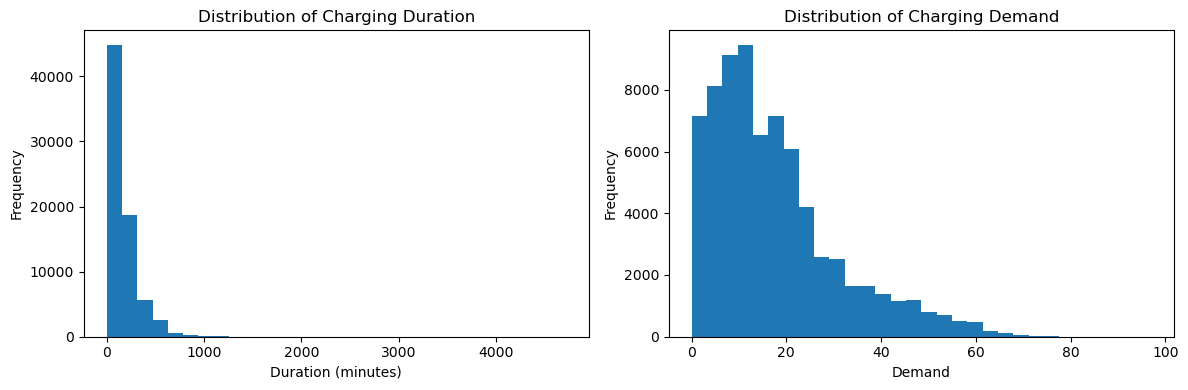

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df["Duration"], bins=30)
ax[0].set_title("Distribution of Charging Duration")
ax[0].set_xlabel("Duration (minutes)")
ax[0].set_ylabel("Frequency")

ax[1].hist(df["Demand"], bins=30)
ax[1].set_title("Distribution of Charging Demand")
ax[1].set_xlabel("Demand")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

<h3 style="color:white">Demand by Location</h3>

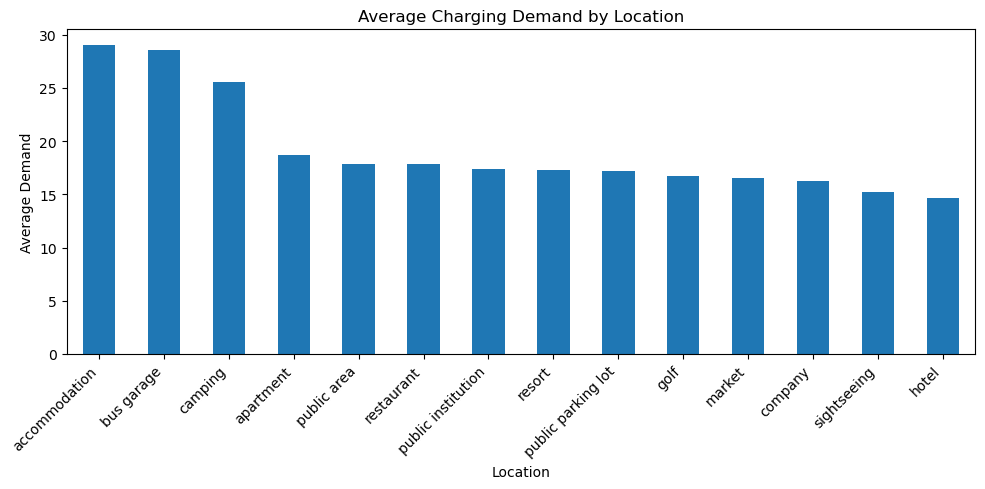

In [7]:
import matplotlib.pyplot as plt

location_demand = df.groupby("Location")["Demand"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
location_demand.plot(kind="bar")
plt.title("Average Charging Demand by Location")
plt.xlabel("Location")
plt.ylabel("Average Demand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

<h3 style="color:white">Demand by Charger Type</h3>

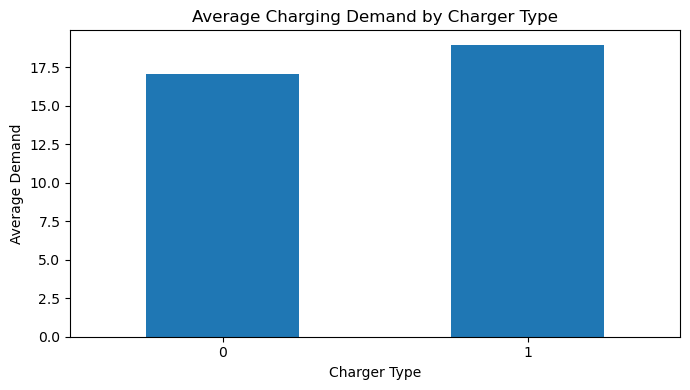

In [8]:
import matplotlib.pyplot as plt

charger_demand = df.groupby("ChargerType")["Demand"].mean()

plt.figure(figsize=(7, 4))
charger_demand.plot(kind="bar")
plt.title("Average Charging Demand by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Average Demand")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<h3 style="color:white">Demand by Charger Company</h3>

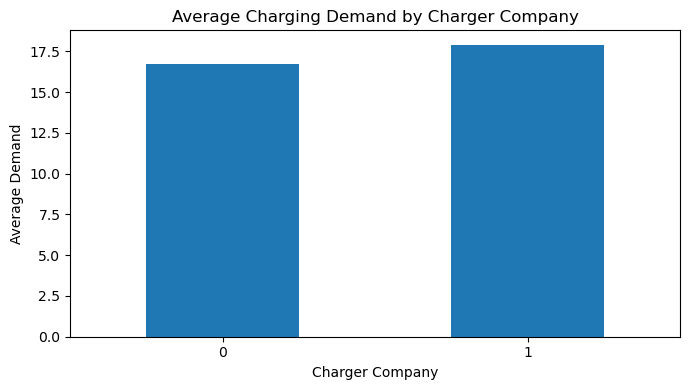

In [9]:
charger_company_demand = df.groupby("ChargerCompany")["Demand"].mean()

plt.figure(figsize=(7, 4))
charger_company_demand.plot(kind="bar")
plt.title("Average Charging Demand by Charger Company")
plt.xlabel("Charger Company")
plt.ylabel("Average Demand")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<h3 style="color:white">Demand Over Time</h3>

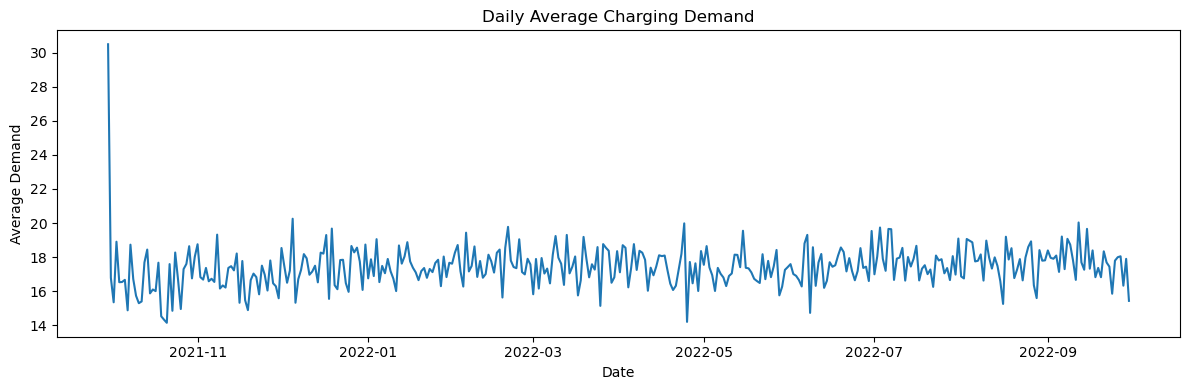

In [12]:
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"], errors="coerce")

df["Date"] = df["StartDatetime"].dt.date

daily_demand = df.groupby("Date")["Demand"].mean()

plt.figure(figsize=(12, 4))
daily_demand.plot()
plt.title("Daily Average Charging Demand")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()

<h3 style="color:white">Charging Duration vs Demand</h3>

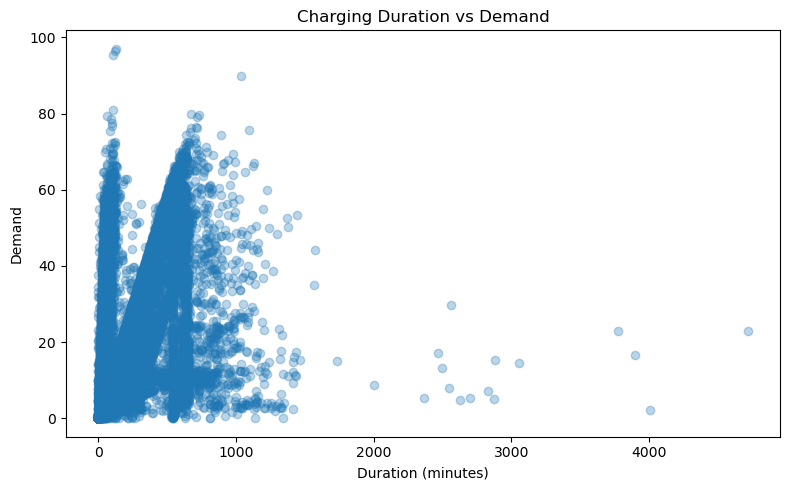

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Duration"], df["Demand"], alpha=0.3)

plt.title("Charging Duration vs Demand")
plt.xlabel("Duration (minutes)")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()

<h3 style="color:white">Demand by Day of the Week</h3>

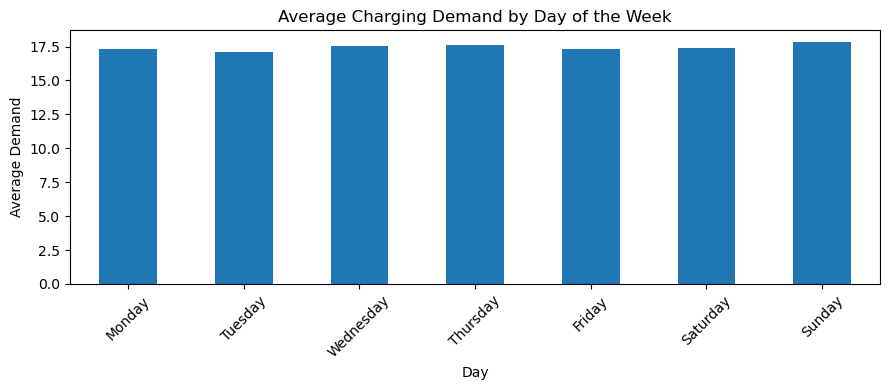

In [14]:
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"], errors="coerce")

df["DayOfWeek"] = df["StartDatetime"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_demand = df.groupby("DayOfWeek")["Demand"].mean().reindex(day_order)

plt.figure(figsize=(9, 4))
day_demand.plot(kind="bar")
plt.title("Average Charging Demand by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h3 style="color:white">Demand by Charging Hour</h3>

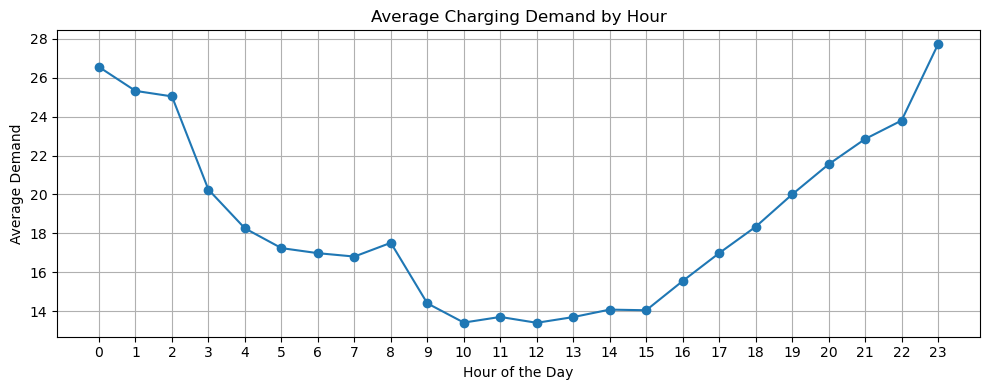

In [15]:
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"], errors="coerce")

df["Hour"] = df["StartDatetime"].dt.hour

hourly_demand = df.groupby("Hour")["Demand"].mean()

plt.figure(figsize=(10, 4))
hourly_demand.plot(kind="line", marker="o")
plt.title("Average Charging Demand by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Demand")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

<h3 style="color:white">Correlation Analysis</h3>

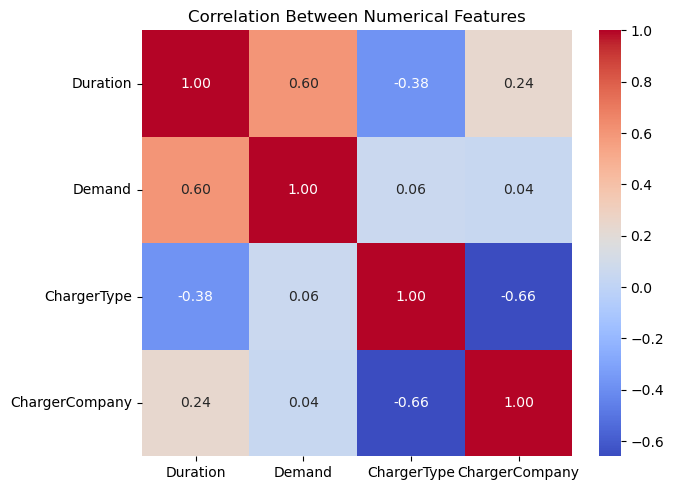

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df[["Duration", "Demand", "ChargerType", "ChargerCompany"]]

correlation = numeric_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

<h3 style="color:white">EDA Summary</h3>

In [17]:
print("Dataset Shape:", df.shape)
print("\nDemand Statistics:")
print(df["Demand"].describe())

print("\nAverage Demand by Location:")
print(df.groupby("Location")["Demand"].mean().sort_values(ascending=False))

print("\nAverage Demand by Charger Type:")
print(df.groupby("ChargerType")["Demand"].mean())

print("\nAverage Demand by Charger Company:")
print(df.groupby("ChargerCompany")["Demand"].mean())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (72826, 16)

Demand Statistics:
count    72826.000000
mean        17.440366
std         13.490614
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

Average Demand by Location:
Location
accommodation         29.055829
bus garage            28.587586
camping               25.525288
apartment             18.744879
public area           17.899891
restaurant            17.813123
public institution    17.399318
resort                17.280838
public parking lot    17.187510
golf                  16.718299
market                16.506272
company               16.248039
sightseeing           15.245129
hotel                 14.702966
Name: Demand, dtype: float64

Average Demand by Charger Type:
ChargerType
0    17.051995
1    18.946402
Name: Demand, dtype: float64

Average Demand by Charger Company:
ChargerCompany
0    16.688881
1    17.886187
Name: Demand, dtype: float64

Missing Values:
Us